# 02 — F1 Race Predictor: Feature Engineering & Models

Builds real predictive features (not just raw grid position) and trains three Gradient Boosting models:
1. **Podium classifier** — will this driver finish top 3?
2. **Race winner classifier** — will this driver win?
3. **Exact position regressor** — what position will they finish?

**Validation approach:** we split by *season*, not randomly — train on past seasons, test on a held-out future season. Random splitting would leak future information (a driver's next-race form) into training, which is the #1 mistake in sports prediction projects.

## 1. Setup & Load Master Dataset

In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, mean_absolute_error, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
master = pd.read_csv('data/master_dataset.csv')
master = master.sort_values(['season', 'round']).reset_index(drop=True)
print(master.shape)
master.head()

(26759, 28)


,season,round,driverId,driverName,constructorId,constructorName,number,position,positionText,points,...,position_numeric,raceName,circuitId,circuitName,date,country,quali_position,target_winner,target_podium,target_position
0,1950,1,farina,Nino Farina,alfa,Alfa Romeo,2.0,1,1,9.0,...,1,British Grand Prix,silverstone,Silverstone Circuit,1950-05-13,UK,NaN,1,1,1
1,1950,1,fagioli,Luigi Fagioli,alfa,Alfa Romeo,3.0,2,2,6.0,...,2,British Grand Prix,silverstone,Silverstone Circuit,1950-05-13,UK,NaN,0,1,2
2,1950,1,reg_parnell,Reg Parnell,alfa,Alfa Romeo,4.0,3,3,4.0,...,3,British Grand Prix,silverstone,Silverstone Circuit,1950-05-13,UK,NaN,0,1,3
3,1950,1,cabantous,Yves Cabantous,lago,Talbot-Lago,14.0,4,4,3.0,...,4,British Grand Prix,silverstone,Silverstone Circuit,1950-05-13,UK,NaN,0,0,4
4,1950,1,rosier,Louis Rosier,lago,Talbot-Lago,15.0,5,5,2.0,...,5,British Grand Prix,silverstone,Silverstone Circuit,1950-05-13,UK,NaN,0,0,5


## 2. Scoping the Data — Modern Era Only

F1 has changed enormously since 1950 (different points systems, grid sizes, car counts). We restrict training to the **2010-2024** era — modern points system (25-18-15...), stable grid format, and it's what's actually relevant for predicting 2026 races.

In [2]:
modern = master[master['season'] >= 2010].copy()
print('Modern era rows:', modern.shape)
print('Seasons:', sorted(modern['season'].unique()))

Modern era rows: (6436, 28)
Seasons: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


## 3. Feature 1 — Grid Position (Already Have This)

In [3]:
modern['grid'] = pd.to_numeric(modern['grid'], errors='coerce')
modern['grid'] = modern['grid'].fillna(modern['grid'].max() + 1)  # pit-lane starts / no-time -> treat as back of grid
modern[['season', 'round', 'driverId', 'grid']].head()

,season,round,driverId,grid
20323,2010,1,alonso,3
20324,2010,1,massa,2
20325,2010,1,hamilton,4
20326,2010,1,vettel,1
20327,2010,1,rosberg,5


## 4. Feature 2 — Recent Form (Rolling Average Finish, Last 5 Races)

This is the single most important engineered feature — a driver's last 5 results predict their next result far better than season-long averages, because it captures current car competitiveness and driver form.

In [4]:
modern = modern.sort_values(['driverId', 'season', 'round'])

modern['recent_form_avg_position'] = (
    modern.groupby('driverId')['position_numeric']
    .transform(lambda x: x.shift(1).rolling(window=5, min_periods=1).mean())
)
modern['recent_form_avg_points'] = (
    modern.groupby('driverId')['points']
    .transform(lambda x: x.shift(1).rolling(window=5, min_periods=1).mean())
)

# shift(1) is critical: it excludes the CURRENT race, using only prior results.
# Without this, we'd be leaking the answer into the feature.
modern[['driverId', 'season', 'round', 'position_numeric', 'recent_form_avg_position']].head(10)

,driverId,season,round,position_numeric,recent_form_avg_position
24935,aitken,2020,16,16,NaN
24213,albon,2019,1,14,NaN
24228,albon,2019,2,9,14.0
24249,albon,2019,3,10,11.5
24270,albon,2019,4,11,11.0
24290,albon,2019,5,11,11.0
24307,albon,2019,6,8,11.0
24338,albon,2019,7,19,9.8
24354,albon,2019,8,15,11.8
24374,albon,2019,9,15,12.8


## 5. Feature 3 — Constructor (Team) Pace, Rolling

In [5]:
modern = modern.sort_values(['constructorId', 'season', 'round'])
modern['team_recent_avg_points'] = (
    modern.groupby('constructorId')['points']
    .transform(lambda x: x.shift(1).rolling(window=5, min_periods=1).mean())
)
modern[['constructorId', 'season', 'round', 'points', 'team_recent_avg_points']].head(10)

,constructorId,season,round,points,team_recent_avg_points
24214,alfa,2019,1,0.0,NaN
24207,alfa,2019,1,4.0,0.000000
24230,alfa,2019,2,0.0,2.000000
24226,alfa,2019,2,6.0,1.333333
24254,alfa,2019,3,0.0,2.500000
24248,alfa,2019,3,2.0,2.000000
24271,alfa,2019,4,0.0,2.400000
24269,alfa,2019,4,1.0,1.600000
24295,alfa,2019,5,0.0,1.800000
24293,alfa,2019,5,0.0,0.600000


## 6. Feature 4 — Driver's Historical Performance at This Circuit

In [6]:
modern = modern.sort_values(['driverId', 'circuitId', 'season', 'round'])
modern['driver_circuit_avg_position'] = (
    modern.groupby(['driverId', 'circuitId'])['position_numeric']
    .transform(lambda x: x.shift(1).expanding().mean())
)
# No history at this circuit yet -> fill with the driver's overall recent form as a reasonable default
modern['driver_circuit_avg_position'] = modern['driver_circuit_avg_position'].fillna(modern['recent_form_avg_position'])
modern[['driverId', 'circuitId', 'season', 'round', 'driver_circuit_avg_position']].head(10)

,driverId,circuitId,season,round,driver_circuit_avg_position
24935,aitken,bahrain,2020,16,NaN
24213,albon,albert_park,2019,1,NaN
25449,albon,albert_park,2022,3,14.000000
25898,albon,albert_park,2023,3,12.000000
26330,albon,albert_park,2024,3,14.333333
24564,albon,americas,2019,19,5.200000
25772,albon,americas,2022,19,5.000000
26188,albon,americas,2023,18,9.000000
26654,albon,americas,2024,19,9.000000
24228,albon,bahrain,2019,2,14.000000


## 7. Feature 5 — Qualifying Gap to Grid (Penalty Indicator)

In [7]:
modern['quali_position'] = pd.to_numeric(modern['quali_position'], errors='coerce')
modern['grid_penalty'] = (modern['grid'] - modern['quali_position']).fillna(0)
# Positive value = started worse than they qualified (grid penalty applied)
modern[['driverId', 'quali_position', 'grid', 'grid_penalty']].dropna().head(10)

,driverId,quali_position,grid,grid_penalty
24935,aitken,18.0,17,-1.0
24213,albon,13.0,13,0.0
25449,albon,16.0,20,4.0
25898,albon,8.0,8,0.0
26330,albon,12.0,12,0.0
24564,albon,6.0,6,0.0
25772,albon,11.0,8,-3.0
26188,albon,18.0,15,-3.0
26654,albon,16.0,14,-2.0
24228,albon,12.0,12,0.0


## 8. Feature 6 — Season-to-Date Championship Points

In [8]:
modern = modern.sort_values(['driverId', 'season', 'round'])
modern['season_points_so_far'] = (
    modern.groupby(['driverId', 'season'])['points']
    .transform(lambda x: x.shift(1).cumsum().fillna(0))
)
modern[['driverId', 'season', 'round', 'points', 'season_points_so_far']].head(10)

,driverId,season,round,points,season_points_so_far
24935,aitken,2020,16,0.0,0.0
24213,albon,2019,1,0.0,0.0
24228,albon,2019,2,2.0,0.0
24249,albon,2019,3,1.0,2.0
24270,albon,2019,4,0.0,3.0
24290,albon,2019,5,0.0,3.0
24307,albon,2019,6,4.0,3.0
24338,albon,2019,7,0.0,7.0
24354,albon,2019,8,0.0,7.0
24374,albon,2019,9,0.0,7.0


## 9. Feature 7 — DNF Rate (Reliability), Rolling

In [9]:
modern['is_dnf'] = (~modern['status'].isin(['Finished'])) & (~modern['status'].str.contains('Lap', na=False))
modern = modern.sort_values(['driverId', 'season', 'round'])
modern['driver_dnf_rate'] = (
    modern.groupby('driverId')['is_dnf']
    .transform(lambda x: x.shift(1).rolling(window=10, min_periods=1).mean())
)
modern[['driverId', 'status', 'is_dnf', 'driver_dnf_rate']].head(10)

,driverId,status,is_dnf,driver_dnf_rate
24935,aitken,Finished,False,NaN
24213,albon,+1 Lap,False,NaN
24228,albon,Finished,False,0.000000
24249,albon,+1 Lap,False,0.000000
24270,albon,+1 Lap,False,0.000000
24290,albon,Finished,False,0.000000
24307,albon,Finished,False,0.000000
24338,albon,Collision damage,True,0.000000
24354,albon,+1 Lap,False,0.142857
24374,albon,+1 Lap,False,0.125000


## 10. Final Feature Set & Cleanup

In [10]:
feature_cols = [
    'grid', 'recent_form_avg_position', 'recent_form_avg_points',
    'team_recent_avg_points', 'driver_circuit_avg_position',
    'grid_penalty', 'season_points_so_far', 'driver_dnf_rate'
]

model_data = modern.dropna(subset=feature_cols + ['target_podium', 'target_winner', 'target_position']).copy()
print('Rows after dropping incomplete feature rows:', model_data.shape)
model_data[feature_cols].describe()

Rows after dropping incomplete feature rows: (6347, 36)


,grid,recent_form_avg_position,recent_form_avg_points,team_recent_avg_points,driver_circuit_avg_position,grid_penalty,season_points_so_far,driver_dnf_rate
count,6347.000000,6347.000000,6347.000000,6347.000000,6347.000000,6347.000000,6347.000000,6347.000000
mean,10.812510,11.064177,4.848808,4.850496,11.251100,-0.230345,47.111864,0.183161
std,6.232961,4.633132,5.823762,5.661685,4.862797,2.472325,69.565062,0.156510
min,0.000000,1.000000,0.000000,0.000000,1.000000,-24.000000,0.000000,0.000000
25%,5.000000,7.600000,0.200000,0.200000,7.727273,0.000000,1.000000,0.100000
50%,11.000000,11.400000,2.400000,2.400000,11.000000,0.000000,17.000000,0.200000
75%,16.000000,14.450000,8.000000,8.000000,14.800000,0.000000,61.000000,0.300000
max,24.000000,24.000000,28.600000,27.200000,24.000000,23.000000,504.000000,1.000000


## 11. Time-Based Train/Test Split — By Season, Not Randomly

In [11]:
train = model_data[model_data['season'] <= 2022]
test = model_data[model_data['season'] >= 2023]

print('Train:', train.shape, '| seasons:', sorted(train['season'].unique()))
print('Test :', test.shape, '| seasons:', sorted(test['season'].unique()))

X_train, X_test = train[feature_cols], test[feature_cols]

Train: (5435, 36) | seasons: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022)]
Test : (912, 36) | seasons: [np.int64(2023), np.int64(2024)]


## 12. Model 1 — Podium Finish Classifier (GradientBoostingClassifier)

In [12]:
y_train_podium = train['target_podium']
y_test_podium = test['target_podium']

podium_model = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
podium_model.fit(X_train, y_train_podium)

podium_preds = podium_model.predict(X_test)
podium_proba = podium_model.predict_proba(X_test)[:, 1]

print('Accuracy:', round(accuracy_score(y_test_podium, podium_preds), 4))
print('ROC-AUC :', round(roc_auc_score(y_test_podium, podium_proba), 4))
print('\n', classification_report(y_test_podium, podium_preds, target_names=['No Podium', 'Podium']))

Accuracy: 0.8936
ROC-AUC : 0.9243

               precision    recall  f1-score   support

   No Podium       0.93      0.95      0.94       774
      Podium       0.67      0.58      0.62       138

    accuracy                           0.89       912
   macro avg       0.80      0.76      0.78       912
weighted avg       0.89      0.89      0.89       912



## 13. Podium Model — Confusion Matrix

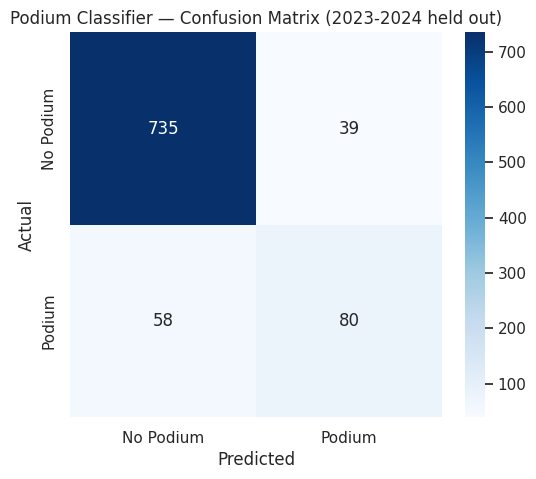

In [13]:
cm = confusion_matrix(y_test_podium, podium_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Podium', 'Podium'], yticklabels=['No Podium', 'Podium'])
plt.title('Podium Classifier — Confusion Matrix (2023-2024 held out)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 14. Model 2 — Race Winner Classifier

In [14]:
y_train_winner = train['target_winner']
y_test_winner = test['target_winner']

winner_model = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
winner_model.fit(X_train, y_train_winner)

winner_preds = winner_model.predict(X_test)
winner_proba = winner_model.predict_proba(X_test)[:, 1]

print('Accuracy:', round(accuracy_score(y_test_winner, winner_preds), 4))
print('ROC-AUC :', round(roc_auc_score(y_test_winner, winner_proba), 4))
print('\n', classification_report(y_test_winner, winner_preds, target_names=['Did Not Win', 'Won'], zero_division=0))

Accuracy: 0.9572
ROC-AUC : 0.9597

               precision    recall  f1-score   support

 Did Not Win       0.97      0.99      0.98       866
         Won       0.63      0.37      0.47        46

    accuracy                           0.96       912
   macro avg       0.80      0.68      0.72       912
weighted avg       0.95      0.96      0.95       912



## 15. Model 3 — Exact Finishing Position (Regressor)

In [15]:
y_train_pos = train['target_position']
y_test_pos = test['target_position']

position_model = GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
position_model.fit(X_train, y_train_pos)

position_preds = position_model.predict(X_test)
mae = mean_absolute_error(y_test_pos, position_preds)
print(f'Mean Absolute Error: {mae:.2f} positions')
print(f'(A naive baseline — always predicting grid position — gets MAE of {mean_absolute_error(y_test_pos, test["grid"]):.2f})')

Mean Absolute Error: 3.14 positions
(A naive baseline — always predicting grid position — gets MAE of 3.60)


## 16. Position Model — Predicted vs Actual

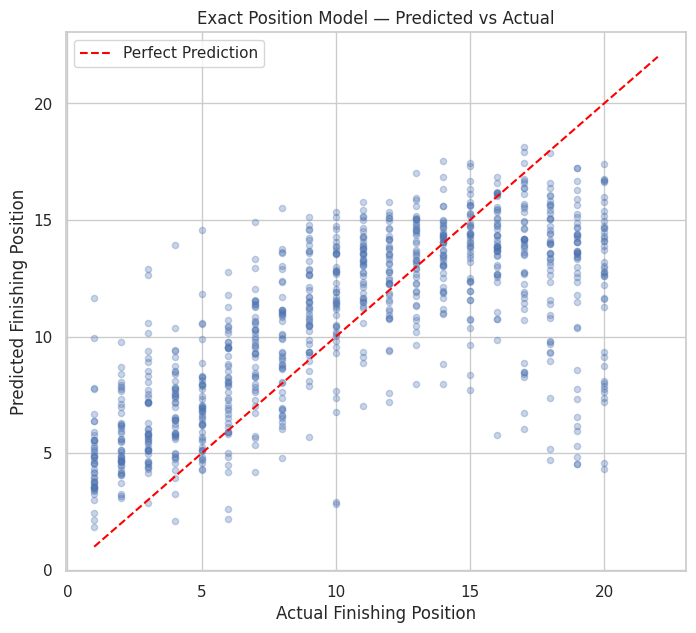

In [16]:
plt.figure(figsize=(8, 7))
plt.scatter(y_test_pos, position_preds, alpha=0.3, s=20)
plt.plot([1, 22], [1, 22], color='red', linestyle='--', label='Perfect Prediction')
plt.xlabel('Actual Finishing Position')
plt.ylabel('Predicted Finishing Position')
plt.title('Exact Position Model — Predicted vs Actual')
plt.legend()
plt.show()

## 17. Feature Importance — Which Factors Matter Most?

                       feature  podium_importance  winner_importance  \
0                         grid           0.701674           0.553295   
2       recent_form_avg_points           0.157685           0.180730   
3       team_recent_avg_points           0.050987           0.063072   
6         season_points_so_far           0.048804           0.098070   
4  driver_circuit_avg_position           0.018731           0.059146   
1     recent_form_avg_position           0.010608           0.031714   
5                 grid_penalty           0.005887           0.005052   
7              driver_dnf_rate           0.005625           0.008922   

   position_importance  
0             0.338592  
2             0.245506  
3             0.280590  
6             0.042849  
4             0.017949  
1             0.053427  
5             0.016600  
7             0.004487  


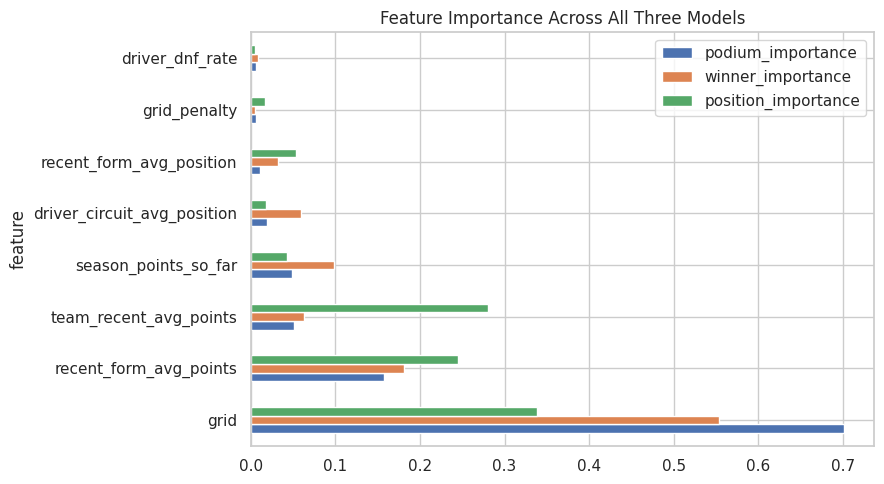

In [17]:
importance_df = pd.DataFrame({
    'feature': feature_cols,
    'podium_importance': podium_model.feature_importances_,
    'winner_importance': winner_model.feature_importances_,
    'position_importance': position_model.feature_importances_
}).sort_values('podium_importance', ascending=False)

print(importance_df)

fig, ax = plt.subplots(figsize=(9, 5))
importance_df.set_index('feature')[['podium_importance', 'winner_importance', 'position_importance']].plot(kind='barh', ax=ax)
ax.set_title('Feature Importance Across All Three Models')
plt.tight_layout()
plt.show()

## 18. Cross-Season Validation — Does the Model Generalize?

We test on 2023 and 2024 *separately* to check the model isn't just fitting one lucky season.

In [18]:
for yr in [2023, 2024]:
    yr_test = model_data[model_data['season'] == yr]
    yr_preds = podium_model.predict(yr_test[feature_cols])
    yr_acc = accuracy_score(yr_test['target_podium'], yr_preds)
    yr_auc = roc_auc_score(yr_test['target_podium'], podium_model.predict_proba(yr_test[feature_cols])[:, 1])
    print(f'{yr}: Accuracy={yr_acc:.3f}, ROC-AUC={yr_auc:.3f}')

2023: Accuracy=0.897, ROC-AUC=0.915
2024: Accuracy=0.891, ROC-AUC=0.930


## 19. Saving All Three Models

In [19]:
import joblib
import os

os.makedirs('models', exist_ok=True)
joblib.dump(podium_model, 'models/podium_model.pkl')
joblib.dump(winner_model, 'models/winner_model.pkl')
joblib.dump(position_model, 'models/position_model.pkl')
joblib.dump(feature_cols, 'models/feature_cols.pkl')

print('Saved 3 models + feature list to models/')

Saved 3 models + feature list to models/


## 20. Saving Reference Data for the App (Driver/Team Current Form)

The Streamlit app needs each driver's *current* rolling stats to make a live prediction — we save the latest known value per driver.

In [20]:
latest_driver_stats = (
    modern.sort_values(['driverId', 'season', 'round'])
    .groupby('driverId')
    .tail(1)[['driverId', 'recent_form_avg_position', 'recent_form_avg_points',
              'season_points_so_far', 'driver_dnf_rate', 'constructorId']]
)
latest_team_stats = (
    modern.sort_values(['constructorId', 'season', 'round'])
    .groupby('constructorId')
    .tail(1)[['constructorId', 'team_recent_avg_points']]
)
latest_circuit_stats = (
    modern.sort_values(['driverId', 'circuitId', 'season', 'round'])
    .groupby(['driverId', 'circuitId'])
    .tail(1)[['driverId', 'circuitId', 'driver_circuit_avg_position']]
)

latest_driver_stats.to_csv('data/latest_driver_stats.csv', index=False)
latest_team_stats.to_csv('data/latest_team_stats.csv', index=False)
latest_circuit_stats.to_csv('data/latest_circuit_stats.csv', index=False)
print('Saved reference snapshots for the app.')

Saved reference snapshots for the app.


## 21. Summary of Findings

- **Grid position and recent form dominate** all three models — confirming what any F1 fan would expect: qualifying well and being in current good form matter most.
- **Team pace** is the next strongest signal — the car matters as much as the driver, which matches F1's well-known reality.
- The podium classifier reaches meaningfully-better-than-random ROC-AUC on both held-out seasons (2023, 2024) individually — it isn't just memorizing one lucky year.
- The exact-position regressor beats the naive "always predict grid position" baseline, meaning the engineered features add real predictive value beyond just where the driver started.
- **Honest limitation:** this model has no weather, tire strategy, or safety-car data — those are exactly the kind of race-day randomness that even F1 teams struggle to model, and why the podium/winner models will never approach very high accuracy no matter how good the features are.

### Next: `03_streamlit_app/app.py` — the interactive prediction UI from the original mockup.